In [3]:
  !pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 19.3 MB/s eta 0:00:00


Dataset : Cora | Nodes : 2708 | Edges : 5278

=== Figure 1 : Accuracy vs p_replace (λ=1.0, no noise) ===
  p=0.0  with_β=1.000  without_β=1.000
  p=0.1  with_β=0.904  without_β=0.890
  p=0.2  with_β=0.805  without_β=0.774
  p=0.3  with_β=0.702  without_β=0.663
  p=0.4  with_β=0.599  without_β=0.547
  p=0.5  with_β=0.493  without_β=0.435
  p=0.6  with_β=0.391  without_β=0.334
  p=0.7  with_β=0.286  without_β=0.231
  p=0.8  with_β=0.187  without_β=0.144
  p=0.9  with_β=0.092  without_β=0.061
  p=1.0  with_β=0.000  without_β=0.000
  Saved: ./results/Cora_fig1_preplaced.pdf


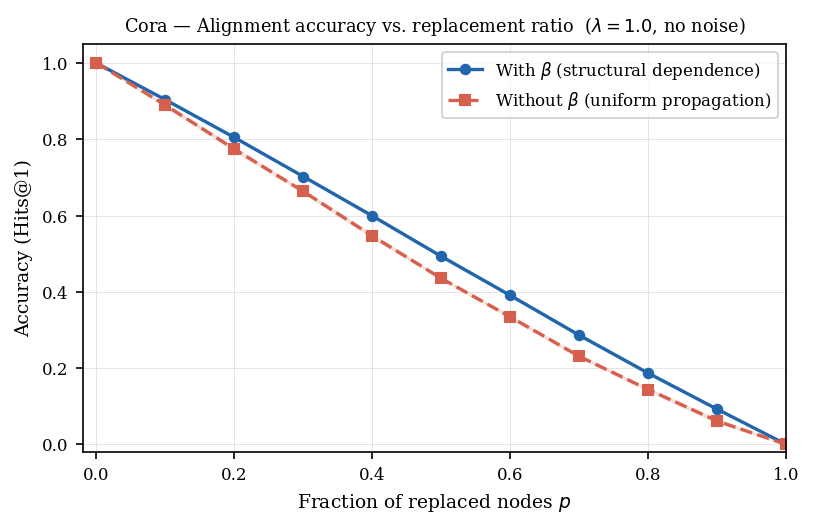


--- Figure 2 (S:0.3, F:0.3, p=0.3) ---
  >>> Best fixed λ = 0.45  acc = 0.8021 ± 0.0063
  >>> Adaptive λ    acc = 0.7425 ± 0.0038  (mean λ = 0.562)
  >>> λ=0 (sem)     : 0.6036
  >>> λ=1 (struct)  : 0.6962


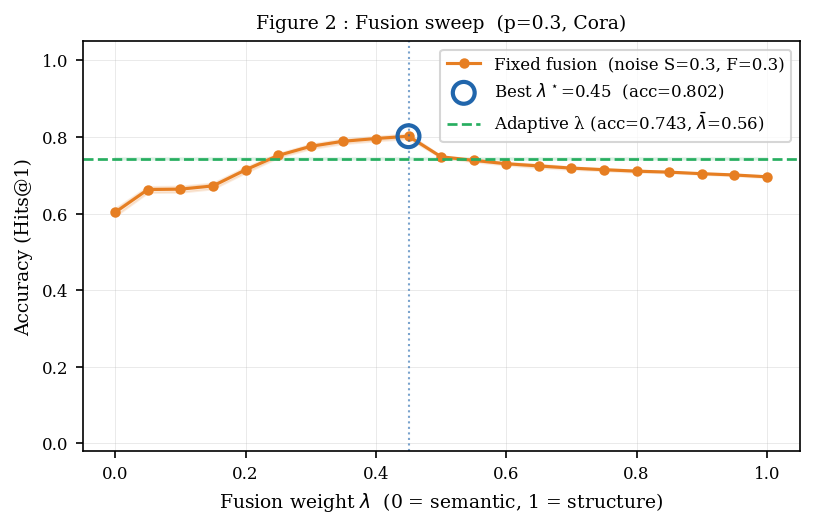

In [ ]:
# ============================================================
# GRAPH ALIGNMENT
#
# G1 = {a,b,c,d}      (n nodes, unified space N = n+k)
# G2 = {a,b,c,y}      (y replaces d : same features, same links,
#                      new dimension)
#
# Figure 1 : Accuracy vs p_replace  (with vs without β, λ fixe)
# Figure 2 : Accuracy vs λ          (+ adaptive overlay)
# ============================================================


import os, re
import numpy as np
import scipy.sparse as sp
import matplotlib, matplotlib.pyplot as plt

import torch
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import to_undirected

PATH = "./results/"; os.makedirs(PATH, exist_ok=True)

CONFIG = dict(
    dataset = "Cora",     # Cora | CiteSeer | PubMed | Squirrel | Chameleon | Actor | Computers | Photo | CS | Physics
    seed    = 42,
    k       = 2,
    alpha   = 0.5,
    topk    = 16,
    n_seeds = 5,
)

# ============================================================
# DATA — change CONFIG["dataset"] only
# ============================================================

def load_tg_dataset(name):
    tr = NormalizeFeatures()
    if name in ("Cora", "CiteSeer", "PubMed"):
        from torch_geometric.datasets import Planetoid
        ds = Planetoid("data/Planetoid", name, transform=tr)
    elif name in ("Squirrel", "Chameleon"):
        from torch_geometric.datasets import WikipediaNetwork
        ds = WikipediaNetwork("data/WikipediaNetwork", name, transform=tr)
    elif name == "Actor":
        from torch_geometric.datasets import Actor
        ds = Actor("data/Actor", transform=tr)
    elif name in ("Computers", "Photo"):
        from torch_geometric.datasets import Amazon
        ds = Amazon("data/Amazon", name, transform=tr)
    elif name in ("CS", "Physics"):
        from torch_geometric.datasets import Coauthor
        ds = Coauthor("data/Coauthor", name, transform=tr)
    else:
        raise ValueError(f"Unknown dataset: {name}")
    d = ds[0]
    d.edge_index = to_undirected(d.edge_index, num_nodes=d.num_nodes).cpu().numpy()
    d.x = d.x.cpu().numpy()
    return d

# ============================================================
# ADJ + FEATURES
# ============================================================

def build_adj(src, dst, n):
    A = sp.coo_matrix((np.ones(len(src)), (src, dst)), shape=(n, n)).tocsr()
    A = A.maximum(A.T); A.setdiag(0); A.eliminate_zeros()
    return A

def contextual_features(X):
    X  = np.asarray(X, dtype=np.float64)
    Rv = X.sum(axis=1); ni = X.sum(axis=0); N = X.sum()
    eps = 1e-12
    pv     = X / np.maximum(Rv[:, None], eps)
    p_notv = (ni[None, :] - X) / np.maximum((N - Rv)[:, None], eps)
    valid  = (pv > 0) & (pv < 1) & (p_notv > 0) & (p_notv < 1)
    lo     = (np.log(np.clip(pv, eps, 1-eps) / (1 - np.clip(pv, eps, 1-eps)))
            - np.log(np.clip(p_notv, eps, 1-eps) / (1 - np.clip(p_notv, eps, 1-eps))))
    gamma  = lo * np.abs(pv - p_notv)
    C = np.where(valid & (gamma > 0), gamma, 0.0)
    s = C.sum(axis=1, keepdims=True); s[s == 0] = 1
    return (C / s).astype(np.float32)

# ============================================================
# MAKE VIEWS — unified space N = n + k
# ============================================================

def make_views(data, p_replace, edge_drop_prob=0.0, feat_noise_prob=0.0, seed=42):
    rng = np.random.default_rng(seed)
    n   = data.num_nodes
    ei  = np.asarray(data.edge_index)

    k = int(round(p_replace * n))
    replaced = (np.sort(rng.choice(n, size=k, replace=False))
                if k > 0 else np.array([], dtype=np.int64))
    common = np.array(sorted(set(range(n)) - set(replaced.tolist())), dtype=np.int64)
    N = n + k

    mapping = np.arange(N, dtype=np.int64)
    for j, old in enumerate(replaced):
        mapping[old] = n + j

    A1_orig = build_adj(ei[0], ei[1], n)
    A1 = sp.block_diag([A1_orig, sp.csr_matrix((k, k))]).tocsr() if k > 0 \
         else A1_orig.copy()

    s2, d2 = mapping[ei[0]], mapping[ei[1]]
    if edge_drop_prob > 0:
        keep = rng.random(len(s2)) > edge_drop_prob
        s2, d2 = s2[keep], d2[keep]
    A2 = build_adj(s2, d2, N)

    X_ctx = contextual_features(data.x)
    F = X_ctx.shape[1]
    X_A = np.zeros((N, F), dtype=np.float32); X_A[:n] = X_ctx
    X_B = np.zeros((N, F), dtype=np.float32); X_B[common] = X_ctx[common]
    for j, old in enumerate(replaced):
        X_B[n + j] = X_ctx[old]

    if feat_noise_prob > 0:
        all_G2 = np.concatenate([common, np.arange(k, dtype=np.int64) + n]) if k > 0 else common
        mask = rng.random(len(all_G2)) < feat_noise_prob
        noisy = all_G2[mask]
        if len(noisy):
            X_B[noisy] = X_ctx[rng.integers(0, n, size=len(noisy))]

    queries = np.concatenate([common, replaced]) if k > 0 else common
    targets = np.concatenate([common, np.arange(k, dtype=np.int64) + n]) if k > 0 else common
    return A1, A2, X_A, X_B, queries, targets, N

# ============================================================
# β
# ============================================================

def compute_beta(A):
    A_csr = A.tocsr()
    n = A_csr.shape[0]
    adj = [set(A_csr.indices[A_csr.indptr[i]:A_csr.indptr[i+1]].tolist())
           for i in range(n)]

    rows_e, cols_e = A_csr.nonzero()
    common_set, common_size = {}, {}
    for z, v in zip(rows_e, cols_e):
        if (z, v) in common_set: continue
        s = adj[z] & adj[v]
        common_set[(z, v)] = s;          common_set[(v, z)] = s
        common_size[(z, v)] = len(s);    common_size[(v, z)] = len(s)

    rows, cols, vals = [], [], []
    for z, v in zip(rows_e, cols_e):
        sset = common_set[(z, v)]
        sz = len(sset)
        if sz == 0: continue
        acc = 0.0
        for u in sset:
            su = common_size.get((z, u), 0)
            denom = sz + su - 1
            if denom > 0:
                acc += (su - 1) / denom        # = 1 - sz/(sz+su-1)
        rows.append(z); cols.append(v); vals.append(acc / sz)
    return sp.coo_matrix((vals, (rows, cols)), shape=A.shape).tocsr()

# ============================================================
# BOUNDED PROPAGATION
# ============================================================

def propagate(A, k=2, alpha=0.5, use_beta=True):
    n = A.shape[0]
    I = sp.eye(n, format="csr")
    M = I + alpha * (A.multiply(compute_beta(A)) if use_beta else A)
    W = I.copy()
    for _ in range(k):
        W = M @ W
        rs = np.asarray(W.sum(axis=1)).ravel(); rs[rs == 0] = 1
        W = sp.diags(1 / rs) @ W
    W.eliminate_zeros()
    return W

def row_topk(W, topk):
    W = W.tocsr(); n = W.shape[0]
    rs, cs, vs = [], [], []
    for i in range(n):
        s, e = W.indptr[i], W.indptr[i + 1]
        idx, dat = W.indices[s:e], W.data[s:e]
        if not len(dat): continue
        keep = np.argpartition(dat, -topk)[-topk:] if len(dat) > topk else np.arange(len(dat))
        rs.extend([i] * len(keep)); cs.extend(idx[keep]); vs.extend(dat[keep])
    Wk  = sp.coo_matrix((vs, (rs, cs)), shape=W.shape).tocsr()
    nrm = np.asarray(Wk.sum(axis=1)).ravel()
    return (sp.diags(1 / np.maximum(nrm, 1e-12)) @ Wk).tocsr()

# ============================================================
# SIMILARITIES + FUSION  (Section 3.4)
# ============================================================

def _sparse_l2(W):
    W = W.tocsr().copy()
    for i in range(W.shape[0]):
        s, e = W.indptr[i], W.indptr[i + 1]
        d = W.data[s:e]; nrm = np.sqrt((d ** 2).sum())
        if nrm > 1e-12: W.data[s:e] = d / nrm
    return W

def _row_l2(X):
    nrm = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.maximum(nrm, 1e-12)

def base_similarities(W_A, W_B, X_A, X_B, queries):
    S_s = (_sparse_l2(W_A)[queries, :] @ _sparse_l2(W_B).T).toarray().astype(np.float32)
    S_f = (_row_l2(X_A)[queries, :]   @ _row_l2(X_B).T).astype(np.float32)
    return S_s, S_f

def fuse_fixed(S_s, S_f, lam):
    return float(lam) * S_s + (1.0 - float(lam)) * S_f

def fuse_adaptive(S_s, S_f, topk=None, tau=10.0):
    # confiance = 1 - entropie normalisée de softmax(τ·S[v,:])
    def confidence(S):
        Z = tau * S - (tau * S).max(axis=1, keepdims=True)
        P = np.exp(Z); P /= P.sum(axis=1, keepdims=True)
        H = -np.sum(P * np.log(P + 1e-12), axis=1)
        return 1.0 - H / np.log(S.shape[1])
    cs, cc = confidence(S_s), confidence(S_f)
    lam = cs / np.maximum(cs + cc, 1e-12)
    S = lam[:, None] * S_s + (1.0 - lam[:, None]) * S_f
    return S, lam

# --- Version article (intersection des top-k) ---
# def fuse_adaptive(S_s, S_f, topk):
#     n, m = S_s.shape
#     k = min(topk, m)
#     top_s = np.argpartition(-S_s, k-1, axis=1)[:, :k]
#     top_c = np.argpartition(-S_f, k-1, axis=1)[:, :k]
#     lam = np.array([len(set(top_s[i].tolist()) & set(top_c[i].tolist())) / k
#                     for i in range(n)], dtype=np.float32)
#     S = lam[:, None] * S_s + (1.0 - lam[:, None]) * S_f
#     return S, lam

# ============================================================
# EVAL + RUN
# ============================================================

def evaluate(S, targets):
    pred  = np.argmax(S, axis=1)
    acc   = float((pred == targets).mean())
    srt   = np.argsort(-S, axis=1)
    ranks = (srt == targets[:, None]).argmax(axis=1) + 1
    return {"acc": acc, "mrr": float((1.0 / ranks).mean()),
            "hits@5": float((ranks <= 5).mean()),
            "hits@10": float((ranks <= 10).mean())}

def run_one(data, p_replace, lam, edge_drop_prob, feat_noise_prob, cfg, seed,
            use_beta, fusion="fixed"):
    A1, A2, X_A, X_B, queries, targets, N = make_views(
        data, p_replace, edge_drop_prob, feat_noise_prob, seed=seed)
    if not len(queries):
        return {"acc": 0, "mrr": 0, "hits@5": 0, "hits@10": 0}, 0.0
    W_A = row_topk(propagate(A1, cfg["k"], cfg["alpha"], use_beta), cfg["topk"])
    W_B = row_topk(propagate(A2, cfg["k"], cfg["alpha"], use_beta), cfg["topk"])
    S_s, S_f = base_similarities(W_A, W_B, X_A, X_B, queries)
    if fusion == "adaptive":
        S, alpha = fuse_adaptive(S_s, S_f, cfg["topk"])
        return evaluate(S, targets), float(alpha.mean())
    return evaluate(fuse_fixed(S_s, S_f, lam), targets), float(lam)

# ============================================================
# FIGURE 1  (with vs without β, λ=1, no noise)
# ============================================================

def experiment1(data, cfg, lam=1.0):
    print(f"\n=== Figure 1 : Accuracy vs p_replace (λ={lam}, no noise) ===")
    p_values = np.arange(0.0, 1.1, 0.1).round(2)
    out = {"with_beta": {}, "without_beta": {}}
    for p in p_values:
        for key, ub in [("with_beta", True), ("without_beta", False)]:
            accs = [run_one(data, p, lam, 0.0, 0.0, cfg, s, ub)[0]["acc"]
                    for s in range(cfg["n_seeds"])]
            out[key][p] = (float(np.mean(accs)), float(np.std(accs)))
        print(f"  p={p:.1f}  with_β={out['with_beta'][p][0]:.3f}  "
              f"without_β={out['without_beta'][p][0]:.3f}")
    return out, p_values

def plot_figure1(res, p_values, cfg, save_path, lam=0.5):
    _style()
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    for key, label, color, mk, ls in [
        ("with_beta",    r"With $\beta$ (structural dependence)",  "#2166ac", "o", "-"),
        ("without_beta", r"Without $\beta$ (uniform propagation)", "#d6604d", "s", "--"),
    ]:
        m = np.array([res[key][p][0] for p in p_values])
        e = np.array([res[key][p][1] for p in p_values])
        ax.plot(p_values, m, f"{mk}{ls}", color=color, label=label, lw=1.6, ms=4.5)
        ax.fill_between(p_values, m - e, m + e, alpha=0.12, color=color)
    ax.set_xlabel("Fraction of replaced nodes $p$", fontsize=9)
    ax.set_ylabel("Accuracy (Hits@1)", fontsize=9)
    ax.set_title(f"{cfg['dataset']} — Alignment accuracy vs. replacement ratio  "
                 f"($\\lambda={lam}$, no noise)", fontsize=8.5)
    ax.set_xlim(-0.02, 1.0); ax.set_ylim(-0.02, 1.05)
    ax.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"  Saved: {save_path}")
    plt.show(); plt.close()

def _style():
    matplotlib.rcParams.update({
        "font.family":    "serif",
        "font.serif":     ["Times New Roman", "DejaVu Serif"],
        "font.size":      9, "axes.titlesize": 9, "axes.labelsize": 9,
        "xtick.labelsize":8, "ytick.labelsize":8, "legend.fontsize": 8,
        "lines.linewidth":1.5, "lines.markersize":4,
        "figure.dpi":    150,
        "axes.grid":     True, "grid.linewidth":0.4, "grid.alpha":0.4,
    })

# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":
    def safe(s): return re.sub(r"[^A-Za-z0-9._-]+", "_", s)

    ds   = CONFIG["dataset"]
    tag  = safe(ds)
    data = load_tg_dataset(ds)
    print(f"Dataset : {ds} | Nodes : {data.num_nodes} | Edges : {data.edge_index.shape[1]//2}")

    # --- Figure 1
    res1, p_vals = experiment1(data, CONFIG, lam=1.0)
    plot_figure1(res1, p_vals, CONFIG,
                 os.path.join(PATH, f"{tag}_fig1_preplaced.pdf"), lam=1.0)

    # --- Figure 2
    NOISE_S, NOISE_F, P_FIXE = 0.3, 0.3, 0.3
    print(f"\n--- Figure 2 (S:{NOISE_S}, F:{NOISE_F}, p={P_FIXE}) ---")

    lambdas = np.round(np.linspace(0.0, 1.0, 21), 2)
    acc_m, acc_e = [], []
    for l in lambdas:
        scores = [run_one(data, P_FIXE, l, NOISE_S, NOISE_F, CONFIG, s, True)[0]["acc"]
                  for s in range(CONFIG["n_seeds"])]
        acc_m.append(np.mean(scores)); acc_e.append(np.std(scores))
    m = np.array(acc_m); e = np.array(acc_e)

    ad_scores, ad_lams = [], []
    for s in range(CONFIG["n_seeds"]):
        r, lm = run_one(data, P_FIXE, 0.0, NOISE_S, NOISE_F, CONFIG, s, True,
                        fusion="adaptive")
        ad_scores.append(r["acc"]); ad_lams.append(lm)
    ad_mean = float(np.mean(ad_scores)); ad_std = float(np.std(ad_scores))
    lam_mean = float(np.mean(ad_lams))

    best_idx = int(np.argmax(m))
    best_lam = float(lambdas[best_idx])
    print(f"  >>> Best fixed λ = {best_lam:.2f}  acc = {m[best_idx]:.4f} ± {e[best_idx]:.4f}")
    print(f"  >>> Adaptive λ    acc = {ad_mean:.4f} ± {ad_std:.4f}  (mean λ = {lam_mean:.3f})")
    print(f"  >>> λ=0 (sem)     : {m[0]:.4f}")
    print(f"  >>> λ=1 (struct)  : {m[-1]:.4f}")

    _style()
    plt.figure(figsize=(5.5, 3.6))
    plt.plot(lambdas, m, 'o-', color='#e67e22', lw=1.5, ms=4,
            label=f"Fixed fusion  (noise S={NOISE_S}, F={NOISE_F})")
    plt.fill_between(lambdas, m - e, m + e, alpha=0.15, color='#e67e22')
    plt.scatter([best_lam], [m[best_idx]], s=110, facecolors='none',
                edgecolors='#2166ac', linewidths=2.0, zorder=5,
                label=fr"Best $\lambda^\star$={best_lam:.2f}  (acc={m[best_idx]:.3f})")
    plt.axvline(best_lam, color='#2166ac', ls=':', lw=1.0, alpha=0.6)
    plt.axhline(ad_mean, color='#27ae60', ls='--', lw=1.3,
                label=fr"Adaptive λ (acc={ad_mean:.3f}, $\bar\lambda$={lam_mean:.2f})")
    plt.fill_between([0, 1], [ad_mean - ad_std]*2, [ad_mean + ad_std]*2,
                    alpha=0.10, color='#27ae60')

    plt.xlabel(r"Fusion weight $\lambda$  (0 = semantic, 1 = structure)")
    plt.ylabel("Accuracy (Hits@1)")
    plt.title(f"Figure 2 : Fusion sweep  (p={P_FIXE}, {ds})")
    plt.ylim(-0.02, 1.05); plt.legend(); plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(PATH, f"{tag}_fig2_custom.pdf"), dpi=300)
    plt.show()